# Random Forest — Classificação de ocorrência de chuva

Este notebook adiciona uma nova etapa ao projeto sem alterar os notebooks anteriores. O objetivo é classificar se ocorreu chuva (`SIM`) ou não (`NAO`) em cada registro horário.

> **Importante para a apresentação:** este é um modelo de classificação do registro do mesmo horário. Para dizer que prevê chuva futura, seria necessário usar somente informações de horas anteriores (variáveis defasadas).

## Por que Random Forest?

Uma árvore de decisão aprende regras como: *se a umidade estiver alta e a pressão estiver baixa, então há maior chance de chuva*. A Random Forest combina muitas árvores e usa a votação entre elas. Isso tende a ser mais estável do que depender de uma única árvore.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline


## 1. Leitura e preparação

Usamos a base adaptada para manter o mesmo alvo já definido pelo grupo. A coluna `CHUVA` é convertida para 1 (SIM) e 0 (NAO). Também criamos mês e hora: elas ajudam o modelo a captar sazonalidade, sem usar a data completa como um identificador.

In [2]:
caminho = '../dataset/INMET_NE_PE_A341_CARUARU_01-01-2025_A_31-12-2025_ADAPTADO.CSV'
df = pd.read_csv(caminho, encoding='iso-8859-1')

# Remove a coluna vazia criada no arquivo de origem, se ela existir.
df = df.drop(columns=['Unnamed: 19'], errors='ignore')

# Cria uma data e hora para ordenar os registros cronologicamente.
hora = df['Hora UTC'].str.extract(r'(\d{4})')[0]
df['DATA_HORA'] = pd.to_datetime(
    df['Data'] + ' ' + hora, format='%Y-%m-%d %H%M'
)
df = df.sort_values('DATA_HORA').reset_index(drop=True)

df['MES'] = df['DATA_HORA'].dt.month
df['HORA'] = df['DATA_HORA'].dt.hour
df['CHUVA_BINARIA'] = (df['CHUVA'] == 'SIM').astype(int)

df[['DATA_HORA', 'CHUVA', 'CHUVA_BINARIA', 'MES', 'HORA']].head()


,DATA_HORA,CHUVA,CHUVA_BINARIA,MES,HORA
0,2025-01-01 00:00:00,NAO,0,1,0
1,2025-01-01 01:00:00,NAO,0,1,1
2,2025-01-01 02:00:00,NAO,0,1,2
3,2025-01-01 03:00:00,NAO,0,1,3
4,2025-01-01 04:00:00,NAO,0,1,4


## 2. Separação cronológica

Em vez de embaralhar as horas, usamos os primeiros 80% dos registros para treino e os últimos 20% para teste. Isso respeita a ordem do tempo: o modelo aprende com o passado e é avaliado em um período posterior.

In [3]:
colunas_remover = ['Data', 'Hora UTC', 'DATA_HORA', 'CHUVA', 'CHUVA_BINARIA']
X = df.drop(columns=colunas_remover)
y = df['CHUVA_BINARIA']

ponto_corte = int(len(df) * 0.80)
X_train, X_test = X.iloc[:ponto_corte], X.iloc[ponto_corte:]
y_train, y_test = y.iloc[:ponto_corte], y.iloc[ponto_corte:]

print(f'Treino: {len(X_train)} registros — {df.loc[ponto_corte - 1, "DATA_HORA"]}')
print(f'Teste:  {len(X_test)} registros — de {df.loc[ponto_corte, "DATA_HORA"]} até {df.loc[len(df) - 1, "DATA_HORA"]}')
print('Proporção de chuva no treino:', y_train.mean().round(3))
print('Proporção de chuva no teste: ', y_test.mean().round(3))


Treino: 7008 registros — 2025-10-19 23:00:00
Teste:  1752 registros — de 2025-10-20 00:00:00 até 2025-12-31 23:00:00
Proporção de chuva no treino: 0.185
Proporção de chuva no teste:  0.015


## 3. Treinamento

A imputação pela mediana é ajustada somente no treino e depois aplicada ao teste. Assim, informações do período de teste não influenciam o treinamento. Não usamos normalização: árvores de decisão e Random Forest não dependem da escala das variáveis.

`class_weight='balanced_subsample'` dá mais importância à classe minoritária (`SIM`) sem remover registros da classe `NAO`.

In [4]:
colunas_numericas = X_train.select_dtypes(include='number').columns.tolist()

preparacao = ColumnTransformer([
    ('numericas', SimpleImputer(strategy='median', add_indicator=True), colunas_numericas)
])

pipeline_rf = Pipeline([
    ('preparacao', preparacao),
    ('modelo', RandomForestClassifier(
        n_estimators=400,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

pipeline_rf.fit(X_train[colunas_numericas], y_train)
y_pred = pipeline_rf.predict(X_test[colunas_numericas])
print('Modelo treinado e previsões criadas:', len(y_pred))

Modelo treinado e previsões criadas: 1752


## 4. Avaliação

A acurácia mostra o percentual total de acertos, mas como há muito mais horas sem chuva, ela não basta sozinha. Por isso também usamos:

- **Precisão:** entre as horas em que o modelo disse que choveria, quantas realmente tiveram chuva.
- **Recall:** entre as horas que realmente tiveram chuva, quantas o modelo encontrou.
- **F1-score:** equilíbrio entre precisão e recall.

,valor
Acurácia,0.988
Precisão (chuva),1.000
Recall (chuva),0.222
F1-score (chuva),0.364


              precision    recall  f1-score   support

         NAO       0.99      1.00      0.99      1725
         SIM       1.00      0.22      0.36        27

    accuracy                           0.99      1752
   macro avg       0.99      0.61      0.68      1752
weighted avg       0.99      0.99      0.98      1752



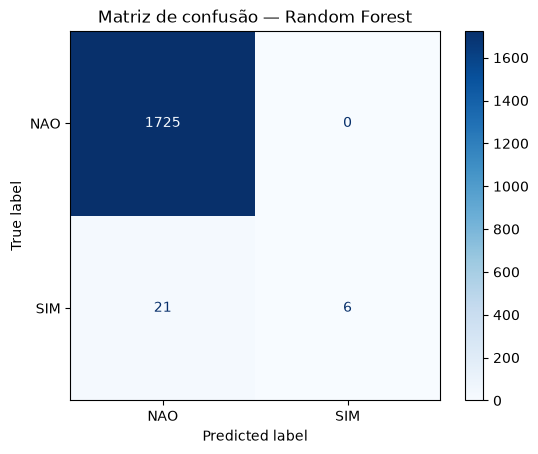

In [5]:
metricas = pd.Series({
    'Acurácia': accuracy_score(y_test, y_pred),
    'Precisão (chuva)': precision_score(y_test, y_pred, zero_division=0),
    'Recall (chuva)': recall_score(y_test, y_pred, zero_division=0),
    'F1-score (chuva)': f1_score(y_test, y_pred, zero_division=0),
})
display(metricas.to_frame('valor').round(3))
print(classification_report(y_test, y_pred, target_names=['NAO', 'SIM'], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['NAO', 'SIM'], cmap='Blues'
)
plt.title('Matriz de confusão — Random Forest')
plt.show()


## 5. Variáveis mais importantes

A importância indica quais variáveis foram mais úteis para as decisões da floresta. Ela não demonstra causa e efeito: uma variável importante ajuda a prever no conjunto analisado, mas não prova que ela causa a chuva.

,importancia
"numericas__UMIDADE RELATIVA DO AR, HORARIA (%)",0.153
numericas__UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),0.108
numericas__UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),0.077
numericas__HORA,0.061
numericas__RADIACAO GLOBAL (Kj/m²),0.051
"numericas__TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",0.050
numericas__TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),0.048
numericas__TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),0.048
"numericas__VENTO, DIREÇÃO HORARIA (gr) (° (gr))",0.048
numericas__PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),0.040


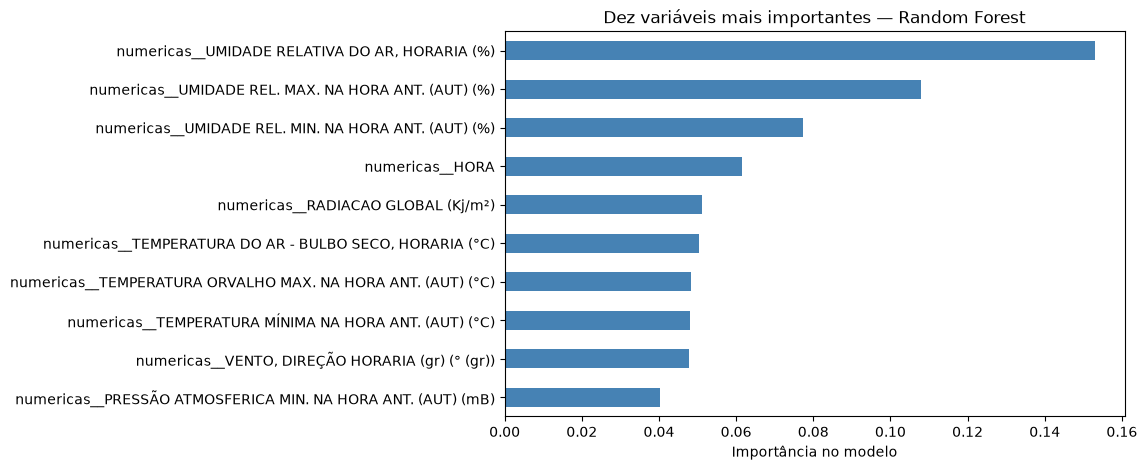

In [6]:
importancias = pd.Series(
    pipeline_rf.named_steps['modelo'].feature_importances_,
    index=pipeline_rf.named_steps['preparacao'].get_feature_names_out(),
).sort_values(ascending=False)

display(importancias.head(10).to_frame('importancia').round(3))
importancias.head(10).sort_values().plot.barh(figsize=(8, 5), color='steelblue')
plt.xlabel('Importância no modelo')
plt.title('Dez variáveis mais importantes — Random Forest')
plt.show()


## Como explicar o resultado

Use esta estrutura na apresentação: *“Treinamos 300 árvores de decisão. Cada árvore avaliou uma combinação diferente de variáveis meteorológicas e a Random Forest reuniu suas votações. Avaliamos o modelo em um período posterior, que não foi usado no treinamento. Além da acurácia, analisamos precision, recall e F1 porque chuva é a classe menos frequente.”*